• Данная практическая работа посвящена расчету фингерпринтов и дескрипторов соединений.

 В рамкках практической работы студенту предстоит:
• Определить различные виды фингерпринтов соединений (MACCS, ECFP,
Morgan);
• Рассчитать структурное сходство соединений (индекс подобия Танимото);
• Рассчитать несколько видов дескрипторов с помощью библиотек RDKit и Mordred


In [ ]:
# Установка библиотек:
! pip install rdkit py3dmol --quiet

# Установка модулей

import pandas as pd # работа с датафреймами
from rdkit.Chem import PandasTools # pandas "для работы с молекулами в датафрейме"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 40.8 MB/s eta 0:00:00


In [ ]:
# Импорт модулей
from rdkit import Chem # основной модуль для базовых функций (чтение SMILES, создание mol, расчет дескрипторов и т.д.)
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole # для настройки визуализации
from rdkit.Chem import rdDepictor # для генерации 2D-координат молекул
from rdkit import DataStructs # для работы с битовыми векторами (фингерпринтами)

# Настройка изображений
IPythonConsole.ipython_useSVG = True # векторная графика
IPythonConsole.molSize = 300, 300 # размер
rdDepictor.SetPreferCoordGen(True) # алгоритм генерации координат

#⚡ 1. Фингерпринты MACCS Keys

📌**Фингерпринт (Fingerprint, FP)** - это двоичный вектор или целочисленная последовательность, которая в цифровой форме кодирует наличие определенных структурных особенностей, фрагментов или свойств молекулы.

📌**MACCS keys (Molecular ACCess System)** - фиксированный набор из 166 битов, где каждый бит соответствует наличию или отсутствию определенного химического фрагмента.

In [ ]:
# Задаем список SMARTS фрагментов (MACCS keys)

smartsPatts = {
  1: ('?', 0),  # ISOTOPE
  #2:('[#104,#105,#106,#107,#106,#109,#110,#111,#112]',0),  # atomic num >103 Not complete
  2: ('[#104]', 0),  # limit the above def'n since the RDKit only accepts up to #104
  3: ('[#32,#33,#34,#50,#51,#52,#82,#83,#84]', 0),  # Group IVa,Va,VIa Rows 4-6
  4: ('[Ac,Th,Pa,U,Np,Pu,Am,Cm,Bk,Cf,Es,Fm,Md,No,Lr]', 0),  # actinide
  5: ('[Sc,Ti,Y,Zr,Hf]', 0),  # Group IIIB,IVB (Sc...)
  6: ('[La,Ce,Pr,Nd,Pm,Sm,Eu,Gd,Tb,Dy,Ho,Er,Tm,Yb,Lu]', 0),  # Lanthanide
  7: ('[V,Cr,Mn,Nb,Mo,Tc,Ta,W,Re]', 0),  # Group VB,VIB,VIIB
  8: ('[!#6;!#1]1~*~*~*~1', 0),  # QAAA@1
  9: ('[Fe,Co,Ni,Ru,Rh,Pd,Os,Ir,Pt]', 0),  # Group VIII (Fe...)
  10: ('[Be,Mg,Ca,Sr,Ba,Ra]', 0),  # Group IIa (Alkaline earth)
  11: ('*1~*~*~*~1', 0),  # 4M Ring
  12: ('[Cu,Zn,Ag,Cd,Au,Hg]', 0),  # Group IB,IIB (Cu..)
  13: ('[#8]~[#7](~[#6])~[#6]', 0),  # ON(C)C
  14: ('[#16]-[#16]', 0),  # S-S
  15: ('[#8]~[#6](~[#8])~[#8]', 0),  # OC(O)O
  16: ('[!#6;!#1]1~*~*~1', 0),  # QAA@1
  17: ('[#6]#[#6]', 0),  #CTC
  18: ('[#5,#13,#31,#49,#81]', 0),  # Group IIIA (B...)
  19: ('*1~*~*~*~*~*~*~1', 0),  # 7M Ring
  20: ('[#14]', 0),  #Si
  21: ('[#6]=[#6](~[!#6;!#1])~[!#6;!#1]', 0),  # C=C(Q)Q
  22: ('*1~*~*~1', 0),  # 3M Ring
  23: ('[#7]~[#6](~[#8])~[#8]', 0),  # NC(O)O
  24: ('[#7]-[#8]', 0),  # N-O
  25: ('[#7]~[#6](~[#7])~[#7]', 0),  # NC(N)N
  26: ('[#6]=;@[#6](@*)@*', 0),  # C$=C($A)$A
  27: ('[I]', 0),  # I
  28: ('[!#6;!#1]~[CH2]~[!#6;!#1]', 0),  # QCH2Q
  29: ('[#15]', 0),  # P
  30: ('[#6]~[!#6;!#1](~[#6])(~[#6])~*', 0),  # CQ(C)(C)A
  31: ('[!#6;!#1]~[F,Cl,Br,I]', 0),  # QX
  32: ('[#6]~[#16]~[#7]', 0),  # CSN
  33: ('[#7]~[#16]', 0),  # NS
  34: ('[CH2]=*', 0),  # CH2=A
  35: ('[Li,Na,K,Rb,Cs,Fr]', 0),  # Group IA (Alkali Metal)
  36: ('[#16R]', 0),  # S Heterocycle
  37: ('[#7]~[#6](~[#8])~[#7]', 0),  # NC(O)N
  38: ('[#7]~[#6](~[#6])~[#7]', 0),  # NC(C)N
  39: ('[#8]~[#16](~[#8])~[#8]', 0),  # OS(O)O
  40: ('[#16]-[#8]', 0),  # S-O
  41: ('[#6]#[#7]', 0),  # CTN
  42: ('F', 0),  # F
  43: ('[!#6;!#1;!H0]~*~[!#6;!#1;!H0]', 0),  # QHAQH
  44: ('[!#1;!#6;!#7;!#8;!#9;!#14;!#15;!#16;!#17;!#35;!#53]', 0),  # OTHER
  45: ('[#6]=[#6]~[#7]', 0),  # C=CN
  46: ('Br', 0),  # BR
  47: ('[#16]~*~[#7]', 0),  # SAN
  48: ('[#8]~[!#6;!#1](~[#8])(~[#8])', 0),  # OQ(O)O
  49: ('[!+0]', 0),  # CHARGE
  50: ('[#6]=[#6](~[#6])~[#6]', 0),  # C=C(C)C
  51: ('[#6]~[#16]~[#8]', 0),  # CSO
  52: ('[#7]~[#7]', 0),  # NN
  53: ('[!#6;!#1;!H0]~*~*~*~[!#6;!#1;!H0]', 0),  # QHAAAQH
  54: ('[!#6;!#1;!H0]~*~*~[!#6;!#1;!H0]', 0),  # QHAAQH
  55: ('[#8]~[#16]~[#8]', 0),  #OSO
  56: ('[#8]~[#7](~[#8])~[#6]', 0),  # ON(O)C
  57: ('[#8R]', 0),  # O Heterocycle
  58: ('[!#6;!#1]~[#16]~[!#6;!#1]', 0),  # QSQ
  59: ('[#16]!:*:*', 0),  # Snot%A%A
  60: ('[#16]=[#8]', 0),  # S=O
  61: ('*~[#16](~*)~*', 0),  # AS(A)A
  62: ('*@*!@*@*', 0),  # A$!A$A
  63: ('[#7]=[#8]', 0),  # N=O
  64: ('*@*!@[#16]', 0),  # A$A!S
  65: ('c:n', 0),  # C%N
  66: ('[#6]~[#6](~[#6])(~[#6])~*', 0),  # CC(C)(C)A
  67: ('[!#6;!#1]~[#16]', 0),  # QS
  68: ('[!#6;!#1;!H0]~[!#6;!#1;!H0]', 0),  # QHQH (&...) SPEC Incomplete
  69: ('[!#6;!#1]~[!#6;!#1;!H0]', 0),  # QQH
  70: ('[!#6;!#1]~[#7]~[!#6;!#1]', 0),  # QNQ
  71: ('[#7]~[#8]', 0),  # NO
  72: ('[#8]~*~*~[#8]', 0),  # OAAO
  73: ('[#16]=*', 0),  # S=A
  74: ('[CH3]~*~[CH3]', 0),  # CH3ACH3
  75: ('*!@[#7]@*', 0),  # A!N$A
  76: ('[#6]=[#6](~*)~*', 0),  # C=C(A)A
  77: ('[#7]~*~[#7]', 0),  # NAN
  78: ('[#6]=[#7]', 0),  # C=N
  79: ('[#7]~*~*~[#7]', 0),  # NAAN
  80: ('[#7]~*~*~*~[#7]', 0),  # NAAAN
  81: ('[#16]~*(~*)~*', 0),  # SA(A)A
  82: ('*~[CH2]~[!#6;!#1;!H0]', 0),  # ACH2QH
  83: ('[!#6;!#1]1~*~*~*~*~1', 0),  # QAAAA@1
  84: ('[NH2]', 0),  #NH2
  85: ('[#6]~[#7](~[#6])~[#6]', 0),  # CN(C)C
  86: ('[C;H2,H3][!#6;!#1][C;H2,H3]', 0),  # CH2QCH2
  87: ('[F,Cl,Br,I]!@*@*', 0),  # X!A$A
  88: ('[#16]', 0),  # S
  89: ('[#8]~*~*~*~[#8]', 0),  # OAAAO
  90:
  ('[$([!#6;!#1;!H0]~*~*~[CH2]~*),$([!#6;!#1;!H0;R]1@[R]@[R]@[CH2;R]1),$([!#6;!#1;!H0]~[R]1@[R]@[CH2;R]1)]',
   0),  # QHAACH2A
  91:
  ('[$([!#6;!#1;!H0]~*~*~*~[CH2]~*),$([!#6;!#1;!H0;R]1@[R]@[R]@[R]@[CH2;R]1),$([!#6;!#1;!H0]~[R]1@[R]@[R]@[CH2;R]1),$([!#6;!#1;!H0]~*~[R]1@[R]@[CH2;R]1)]',
   0),  # QHAAACH2A
  92: ('[#8]~[#6](~[#7])~[#6]', 0),  # OC(N)C
  93: ('[!#6;!#1]~[CH3]', 0),  # QCH3
  94: ('[!#6;!#1]~[#7]', 0),  # QN
  95: ('[#7]~*~*~[#8]', 0),  # NAAO
  96: ('*1~*~*~*~*~1', 0),  # 5 M ring
  97: ('[#7]~*~*~*~[#8]', 0),  # NAAAO
  98: ('[!#6;!#1]1~*~*~*~*~*~1', 0),  # QAAAAA@1
  99: ('[#6]=[#6]', 0),  # C=C
  100: ('*~[CH2]~[#7]', 0),  # ACH2N
  101:
  ('[$([R]@1@[R]@[R]@[R]@[R]@[R]@[R]@[R]1),$([R]@1@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]1),$([R]@1@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]1),$([R]@1@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]1),$([R]@1@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]1),$([R]@1@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]1),$([R]@1@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]@[R]1)]',
   0),  # 8M Ring or larger. This only handles up to ring sizes of 14
  102: ('[!#6;!#1]~[#8]', 0),  # QO
  103: ('Cl', 0),  # CL
  104: ('[!#6;!#1;!H0]~*~[CH2]~*', 0),  # QHACH2A
  105: ('*@*(@*)@*', 0),  # A$A($A)$A
  106: ('[!#6;!#1]~*(~[!#6;!#1])~[!#6;!#1]', 0),  # QA(Q)Q
  107: ('[F,Cl,Br,I]~*(~*)~*', 0),  # XA(A)A
  108: ('[CH3]~*~*~*~[CH2]~*', 0),  # CH3AAACH2A
  109: ('*~[CH2]~[#8]', 0),  # ACH2O
  110: ('[#7]~[#6]~[#8]', 0),  # NCO
  111: ('[#7]~*~[CH2]~*', 0),  # NACH2A
  112: ('*~*(~*)(~*)~*', 0),  # AA(A)(A)A
  113: ('[#8]!:*:*', 0),  # Onot%A%A
  114: ('[CH3]~[CH2]~*', 0),  # CH3CH2A
  115: ('[CH3]~*~[CH2]~*', 0),  # CH3ACH2A
  116: ('[$([CH3]~*~*~[CH2]~*),$([CH3]~*1~*~[CH2]1)]', 0),  # CH3AACH2A
  117: ('[#7]~*~[#8]', 0),  # NAO
  118: ('[$(*~[CH2]~[CH2]~*),$(*1~[CH2]~[CH2]1)]', 1),  # ACH2CH2A > 1
  119: ('[#7]=*', 0),  # N=A
  120: ('[!#6;R]', 1),  # Heterocyclic atom > 1 (&...) Spec Incomplete
  121: ('[#7;R]', 0),  # N Heterocycle
  122: ('*~[#7](~*)~*', 0),  # AN(A)A
  123: ('[#8]~[#6]~[#8]', 0),  # OCO
  124: ('[!#6;!#1]~[!#6;!#1]', 0),  # QQ
  125: ('?', 0),  # Aromatic Ring > 1
  126: ('*!@[#8]!@*', 0),  # A!O!A
  127: ('*@*!@[#8]', 1),  # A$A!O > 1 (&...) Spec Incomplete
  128:
  ('[$(*~[CH2]~*~*~*~[CH2]~*),$([R]1@[CH2;R]@[R]@[R]@[R]@[CH2;R]1),$(*~[CH2]~[R]1@[R]@[R]@[CH2;R]1),$(*~[CH2]~*~[R]1@[R]@[CH2;R]1)]',
   0),  # ACH2AAACH2A
  129: ('[$(*~[CH2]~*~*~[CH2]~*),$([R]1@[CH2]@[R]@[R]@[CH2;R]1),$(*~[CH2]~[R]1@[R]@[CH2;R]1)]',
        0),  # ACH2AACH2A
  130: ('[!#6;!#1]~[!#6;!#1]', 1),  # QQ > 1 (&...)  Spec Incomplete
  131: ('[!#6;!#1;!H0]', 1),  # QH > 1
  132: ('[#8]~*~[CH2]~*', 0),  # OACH2A
  133: ('*@*!@[#7]', 0),  # A$A!N
  134: ('[F,Cl,Br,I]', 0),  # X (HALOGEN)
  135: ('[#7]!:*:*', 0),  # Nnot%A%A
  136: ('[#8]=*', 1),  # O=A>1
  137: ('[!C;!c;R]', 0),  # Heterocycle
  138: ('[!#6;!#1]~[CH2]~*', 1),  # QCH2A>1 (&...) Spec Incomplete
  139: ('[O;!H0]', 0),  # OH
  140: ('[#8]', 3),  # O > 3 (&...) Spec Incomplete
  141: ('[CH3]', 2),  # CH3 > 2  (&...) Spec Incomplete
  142: ('[#7]', 1),  # N > 1
  143: ('*@*!@[#8]', 0),  # A$A!O
  144: ('*!:*:*!:*', 0),  # Anot%A%Anot%A
  145: ('*1~*~*~*~*~*~1', 1),  # 6M ring > 1
  146: ('[#8]', 2),  # O > 2
  147: ('[$(*~[CH2]~[CH2]~*),$([R]1@[CH2;R]@[CH2;R]1)]', 0),  # ACH2CH2A
  148: ('*~[!#6;!#1](~*)~*', 0),  # AQ(A)A
  149: ('[C;H3,H4]', 1),  # CH3 > 1
  150: ('*!@*@*!@*', 0),  # A!A$A!A
  151: ('[#7;!H0]', 0),  # NH
  152: ('[#8]~[#6](~[#6])~[#6]', 0),  # OC(C)C
  153: ('[!#6;!#1]~[CH2]~*', 0),  # QCH2A
  154: ('[#6]=[#8]', 0),  # C=O
  155: ('*!@[CH2]!@*', 0),  # A!CH2!A
  156: ('[#7]~*(~*)~*', 0),  # NA(A)A
  157: ('[#6]-[#8]', 0),  # C-O
  158: ('[#6]-[#7]', 0),  # C-N
  159: ('[#8]', 1),  # O>1
  160: ('[C;H3,H4]', 0),  #CH3
  161: ('[#7]', 0),  # N
  162: ('a', 0),  # Aromatic
  163: ('*1~*~*~*~*~*~1', 0),  # 6M Ring
  164: ('[#8]', 0),  # O
  165: ('[R]', 0),  # Ring
  166: ('?', 0),  # Fragments  FIX: this can't be done in SMARTS
}

In [ ]:
def compile_maccs_keys(smarts_dict):
    """
    Принимает текстовый словарь smartsPatts.
    Возвращает список maccsKeys со скомпилированными объектами RDKit.
    """
    # Создаем «пустую полку» фиксированной длины
    maccs_keys_list = [(None, 0)] * len(smarts_dict.keys())

    # Заполняем список, переводя строки SMARTS в объекты RDKit
    for key in smarts_dict.keys():
        patt_string, count_value = smarts_dict[key]
        if patt_string != '?':
            sma = Chem.MolFromSmarts(patt_string)
            if sma:
                # Записываем в список со сдвигом на -1
                maccs_keys_list[key - 1] = (sma, count_value)

    return maccs_keys_list

maccs_keys_list = compile_maccs_keys(smartsPatts)

In [ ]:
print(maccs_keys_list)

[(None, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc614d0>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc612a0>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61540>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc615b0>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61620>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61690>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61700>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61770>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc617e0>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61850>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc618c0>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61930>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc619a0>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61a10>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61a80>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61af0>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61b60>, 0), (<rdkit.Chem.rdchem.Mol object at 0x7f33afc61bd0>, 0)

In [ ]:
from rdkit.DataStructs import SparseBitVect # Для создания разряженного битового вектора

def fp_generator(mol, maccs_keys_list):
    """
    Принимает молекулу и уже готовый (скомпилированный) список prepared_keys
    """
    # Создаем пустой бинарный вектор
    fingerprint = SparseBitVect(len(maccs_keys_list) + 1)

    # По очереди примеряем каждый химический шаблон к молекуле
    for i, (patt, count) in enumerate(maccs_keys_list):
        if patt is not None:
            # Если нужно просто проверить НАЛИЧИЕ фрагмента
            if count == 0:
                fingerprint[i + 1] = mol.HasSubstructMatch(patt)
            # Если нужно проверить КОЛИЧЕСТВО
            else:
                matches = mol.GetSubstructMatches(patt)
                if len(matches) > count:
                    fingerprint[i + 1] = 1

    return fingerprint

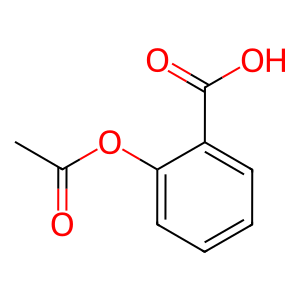

In [ ]:
aspirin = Chem.MolFromSmiles('CC(=O)Oc1ccccc1C(=O)O')
aspirin

In [ ]:
aspirin_fp = fp_generator(aspirin, maccs_keys_list)
print("Включенные биты:", tuple(aspirin_fp.GetOnBits()))
print("Фингерпринт (MACCS) аспирина:" , aspirin_fp.ToBitString())

Включенные биты: (89, 113, 123, 126, 127, 136, 139, 140, 143, 144, 146, 150, 152, 154, 157, 159, 160, 162, 163, 164, 165)
Фингерпринт (MACCS) аспирина: 00000000000000000000000000000000000000000000000000000000000000000000000000000000000000000100000000000000000000000100000000010011000000001001100110100010101001011011110


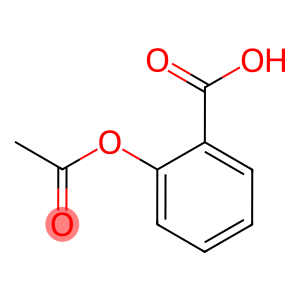

In [ ]:
aspirin.GetSubstructMatch(Chem.MolFromSmarts('[#8]')) # Функция ищет и визуаизрует совпадение
aspirin

In [ ]:
# Генерация фингерпринта MACCSkey для аспирина
from rdkit.Chem import MACCSkeys

aspirin_fp_maccs = MACCSkeys.GenMACCSKeys(aspirin) # Функция MACCSkeys.GenMACCSKeys возващает объект SparseBitVect (разряженный вектор)
print(len(aspirin_fp_maccs))
print(list(aspirin_fp_maccs))

167
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0]


#⚡ 2. Фингерпринты ECFP/Моргана

📌**Фингерпринты ECFP/Моргана** -фингерпринты с расширенной связностью (Extended-Connectivity Fingerprints, ECFP). Основа – модифицированный алгоритм Моргана.

In [ ]:
import hashlib
from rdkit import Chem

def morgan_fp(mol, n_bits=1024):
    """
    Генерирует классический фингерпринт Моргана для Радиуса 0 (ECFP0).
    Кодирует только собственные свойства атомов без учета их соседей.
    """
    all_fragment_hashes = set()

    # Проходим по каждому атому в молекуле
    for atom in mol.GetAtoms():

        # Собираем 7 классических свойств атома
        features = (
            atom.GetDegree(),          # Количество "тяжелых" (не водородов) соседей
            atom.GetTotalValence(),    # Полная валентность атома
            atom.GetAtomicNum(),       # Атомный номер (6 для C, 8 для O, 7 для N и т.д.)
            int(atom.GetMass()),       # Округленная масса атома
            atom.GetFormalCharge(),    # Формальный заряд атома (например, 0, -1, 1)
            atom.GetTotalNumHs(),      # Общее количество присоединенных водородов
            int(atom.GetIsAromatic())  # Флаг ароматичности: 1 (да) или 0 (нет)
        )
        # Хэшируем кортеж свойств через SHA-256 (хэш-функция)
        feat_bytes = str(features).encode('utf-8')
        atom_hash = int(hashlib.sha256(feat_bytes).hexdigest(), 16)

        # Сохраняем получившийся хэш уникального типа атома
        all_fragment_hashes.add(atom_hash)

        print(f" Атом {atom.GetSymbol()} c индексом {atom.GetIdx()}: описание атома (features) {features}, кторое кодируется в число {atom_hash}, которое соответствует индексу бита {atom_hash % n_bits}")

    # Переносим хэши в бинарный вектор фиксированной длины
    bit_vector = [0] * n_bits
    for frag_hash in all_fragment_hashes:
        bit_index = frag_hash % n_bits
        bit_vector[bit_index] = 1

    return bit_vector

# =====================================================================
# Пример запуска на Аспирине
# =====================================================================

fp_r0 = morgan_fp(aspirin, n_bits=64)
print(fp_r0)

 Атом C c индексом 0: описание атома (features) (1, 4, 6, 12, 0, 3, 0), кторое кодируется в число 43347608488195899405772091951000426916303239521040357146585090321197647509545, которое соответствует индексу бита 41
 Атом C c индексом 1: описание атома (features) (3, 4, 6, 12, 0, 0, 0), кторое кодируется в число 62581387430884618198364327929168871992998288245356204134802293400338078747790, которое соответствует индексу бита 14
 Атом O c индексом 2: описание атома (features) (1, 2, 8, 15, 0, 0, 0), кторое кодируется в число 67706924450339054766933698211683376682461127592298138544308943973981856566656, которое соответствует индексу бита 0
 Атом O c индексом 3: описание атома (features) (2, 2, 8, 15, 0, 0, 0), кторое кодируется в число 102010447637657315619486361222629168389230678524144746371619387902795810952251, которое соответствует индексу бита 59
 Атом C c индексом 4: описание атома (features) (3, 4, 6, 12, 0, 0, 1), кторое кодируется в число 911447783315822853231634499890624995758590

In [ ]:
import random # Для генерации случайных чисел

def collision_simulator(num_fragments=100, bit_size=64):
    """
    Симулирует процесс перевода хэша в битовый вектор
    """
    random.seed(42)
    unique_hashes = [random.randint(100000, 999999) for _ in range(num_fragments)]

    all_bit_indexes = set()
    for i in unique_hashes:
      bit_index = i % bit_size
      all_bit_indexes.add(bit_index)
    print("Кол-во уникальных индексов из 100: ", len(set(all_bit_indexes)))
    return

print("---Короткий вектор (64 бит) ---")
collision_simulator(num_fragments=100, bit_size=64)

print("---Длинный вектор (1024 бит) ---")
collision_simulator(num_fragments=100, bit_size=1024)

---Короткий вектор (64 бит) ---
Кол-во уникальных индексов из 100:  58
---Длинный вектор (1024 бит) ---
Кол-во уникальных индексов из 100:  96


In [ ]:
# Генерация фингерпринта Morgan для аспирина
from rdkit.Chem import rdFingerprintGenerator


fpg = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048) # Создаем генератор фингерпринтов с параметрами radius (кол-во связей), fpSize (кол-во бит)
aspirin_fp_morgan = fpg.GetFingerprint(aspirin) # Генерация фингепринта Morgan
print(len(aspirin_fp_morgan))
print(list(aspirin_fp_morgan))

#aspirin_fp_morgan = fpg.GetCountFingerprint(aspirin)
#print(f"Ненулевые фрагменты (индекс: кол-во):\n{aspirin_fp_morgan.GetNonzeroElements()}")
#print(list(aspirin_fp_morgan))

2048
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

#⚡ 3. Рассчет структурного сходства

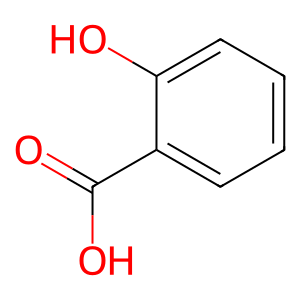

In [ ]:
salicylic_acid = Chem.MolFromSmiles('C1=CC=C(C(=C1)C(=O)O)O')
salicylic_acid

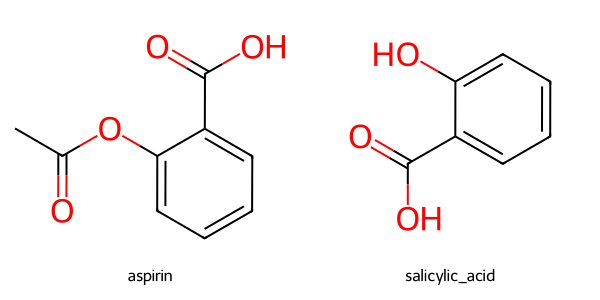

In [ ]:
img = Draw.MolsToGridImage(
    [aspirin, salicylic_acid],
    molsPerRow=2,
    subImgSize=IPythonConsole.molSize,
    legends=['aspirin', 'salicylic_acid'],
)
display(img)

📌**Индексы подобия Танимото T(A,B) и Дайса Dice(A,B)** - количественные оценки степени сходства двух молекул на основе их структурных или физико-химических характеристик.

In [ ]:
salicylic_acid_fp_maccs = MACCSkeys.GenMACCSKeys(salicylic_acid)
salicylic_acid_fp_morgan = fpg.GetFingerprint(salicylic_acid)

In [ ]:
# TanimotoSimilarity - функция для расчета коэффициента подобия Танимото

#print('T(аспирин, аспирин),maccs = 'f"{DataStructs.TanimotoSimilarity(aspirin_fp_maccs, aspirin_fp_maccs):.2f}")
#print('T(аспирин, салициловая кислота),maccs = 'f"{DataStructs.TanimotoSimilarity(aspirin_fp_maccs, salicylic_acid_fp_maccs):.2f}")
#print('T(аспирин, салициловая кислота),morgan = 'f"{DataStructs.TanimotoSimilarity(aspirin_fp_morgan, salicylic_acid_fp_morgan):.2f}")

In [ ]:
# DiceSimilarity - функция для расчета коэффициента подобия Dice
print('Dice(аспирин, салициловая кислота),morgan = 'f"{DataStructs.DiceSimilarity(aspirin_fp_morgan, salicylic_acid_fp_morgan):.2f}")

Dice(аспирин, салициловая кислота),morgan = 0.62


In [ ]:
smiles = [
    'CC(=O)Oc1ccccc1C(=O)O',
    'C1=CC=C(C(=C1)C(=O)O)O',
    'C1=CC=C(C(=C1)C(=O)N)O',
    'C1=CC(=C(C=C1C2=C(C=C(C=C2)F)F)C(=O)O)O'
]

name = [
    'aspirin',
    'salicylic_acid',
    'salicylamide',
    'diflunisal'
]

df = pd.DataFrame({
    'SMILES': smiles,
    'name': name
})

df['Structure'] = [Chem.MolFromSmiles(s) for s in df['SMILES']] # добавляем столбцец "Structure" с mol для отображения структур молекул
PandasTools.RenderImagesInAllDataFrames(images=False) # режим отображения структур

df

,SMILES,name,Structure
0,CC(=O)Oc1ccccc1C(=O)O,aspirin,<rdkit.Chem.rdchem.Mol object at 0x7f33afc61bd0>
1,C1=CC=C(C(=C1)C(=O)O)O,salicylic_acid,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ce40>
2,C1=CC=C(C(=C1)C(=O)N)O,salicylamide,<rdkit.Chem.rdchem.Mol object at 0x7f33af66cc80>
3,C1=CC(=C(C=C1C2=C(C=C(C=C2)F)F)C(=O)O)O,diflunisal,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ceb0>


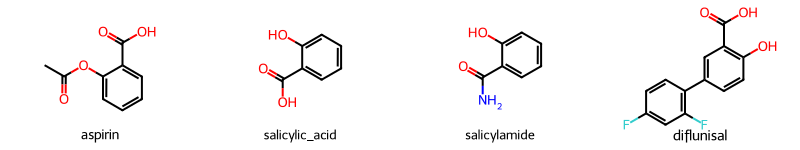

In [ ]:
Draw.MolsToGridImage(
    df["Structure"].to_list(),
    molsPerRow=4,
    subImgSize=(200, 150),
    legends=df["name"].to_list(),
)

In [ ]:
# Добавляем фингерпринты в датафрейм

df['maccs'] = df.Structure.apply(MACCSkeys.GenMACCSKeys)
df['mrg'] = df.Structure.apply(fpg.GetFingerprint)
df

,SMILES,name,Structure,maccs,mrg
0,CC(=O)Oc1ccccc1C(=O)O,aspirin,<rdkit.Chem.rdchem.Mol object at 0x7f33afc61bd0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,C1=CC=C(C(=C1)C(=O)O)O,salicylic_acid,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ce40>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,C1=CC=C(C(=C1)C(=O)N)O,salicylamide,<rdkit.Chem.rdchem.Mol object at 0x7f33af66cc80>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,C1=CC(=C(C=C1C2=C(C=C(C=C2)F)F)C(=O)O)O,diflunisal,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ceb0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [ ]:
def simmilarity (df=df, fg_type='mrg', sim_index='T,mrg'):
  """
  Функция для рассчета индеса подобия Танимото

  Аргументы:
               df - датафрейм (по умолчанию 'df')
               fg_type - тип фингерпринтов, столбец датафрейма (по умолчанию -'mrg')
               sim_index - название столбца датафрейма, в котором будут записаны индексы подобия (по умолчанию - 'T,mrg')
  """
  ref_mol = df[fg_type][0] # Референсная молекула - относительно которой сравниваем
  mol_list = df[fg_type].to_list() # Список фингерпринтов всех соединений
  df[sim_index] = DataStructs.BulkTanimotoSimilarity(ref_mol, mol_list) # Расчет индекса подобия Танимото для нескольких соединений
  df = df.sort_values(by=sim_index, ascending=False) # Сортируем строки датафрейма по индексу подобия по убыванию

  return df

In [ ]:
# Расчитываем идекс подобия танимото для всех соединений по фингерпринтам Моргана
df = simmilarity(df, 'mrg', 'T,mrg')
df

,SMILES,name,Structure,maccs,mrg,"T,mrg"
0,CC(=O)Oc1ccccc1C(=O)O,aspirin,<rdkit.Chem.rdchem.Mol object at 0x7f33afc61bd0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.000000
1,C1=CC=C(C(=C1)C(=O)O)O,salicylic_acid,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ce40>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.448276
2,C1=CC=C(C(=C1)C(=O)N)O,salicylamide,<rdkit.Chem.rdchem.Mol object at 0x7f33af66cc80>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.303030
3,C1=CC(=C(C=C1C2=C(C=C(C=C2)F)F)C(=O)O)O,diflunisal,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ceb0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.250000


In [ ]:
# Фильтрация датафрейма по индексу подобия
df_filtred = df[df["T,mrg"] > 0.4]
df_filtred

,SMILES,name,Structure,maccs,mrg,"T,mrg"
0,CC(=O)Oc1ccccc1C(=O)O,aspirin,<rdkit.Chem.rdchem.Mol object at 0x7f33afc61bd0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.000000
1,C1=CC=C(C(=C1)C(=O)O)O,salicylic_acid,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ce40>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.448276


#⚡ 4. Дескипторы RDKt

## ✔️ 0-2D Дескрипторы

In [ ]:
from rdkit.Chem import Descriptors # модуль для расчета дескрипторов (https://www.rdkit.org/docs/source/rdkit.Chem.Descriptors.html)

print(len(Descriptors._descList))
print(Descriptors._descList[:5])

217
[('MaxAbsEStateIndex', <function MaxAbsEStateIndex at 0x7f33b0d01f80>), ('MaxEStateIndex', <function MaxEStateIndex at 0x7f33b0d03240>), ('MinAbsEStateIndex', <function MinAbsEStateIndex at 0x7f33b0d02480>), ('MinEStateIndex', <function MinEStateIndex at 0x7f33b0d027a0>), ('qed', <function qed at 0x7f33af6171a0>)]


In [ ]:
# Расчет молекулярной массы аспирина (MolWt)
Descriptors.MolWt(aspirin)

180.15899999999996

In [ ]:
def getMolDescriptors(mol, desc_names=None, missingVal=None):
    ''' Функция для расчета некольких дескрипторов

    Аргументы:
                 mol - соединение
                 desc_names - список дескрипторов (по умолчанию None)
                 missingVal - проверка на некорректные/пропущенные начения (по умолчанию None)

    '''
    res = {}
    for nm, fn in Descriptors._descList:
        # Если передан список и текущего дескриптора в нем нет — пропускаем его
        if desc_names is not None and nm not in desc_names:
            continue

        try:
            val = fn(mol)
        except:
            import traceback
            traceback.print_exc()
            val = missingVal
        res[nm] = val
    return res

In [ ]:
# Расчет всех дескрипторов
getMolDescriptors(aspirin)

{'MaxAbsEStateIndex': np.float64(10.611948223733938),
 'MaxEStateIndex': np.float64(10.611948223733938),
 'MinAbsEStateIndex': np.float64(0.01601851851851821),
 'MinEStateIndex': np.float64(-1.1140277777777776),
 'qed': 0.5501217966938848,
 'SPS': 9.307692307692308,
 'MolWt': 180.15899999999996,
 'HeavyAtomMolWt': 172.09499999999997,
 'ExactMolWt': 180.042258736,
 'NumValenceElectrons': 68,
 'NumRadicalElectrons': 0,
 'MaxPartialCharge': 0.33900378687731025,
 'MinPartialCharge': -0.4775395271554559,
 'MaxAbsPartialCharge': 0.4775395271554559,
 'MinAbsPartialCharge': 0.33900378687731025,
 'FpDensityMorgan1': 1.3076923076923077,
 'FpDensityMorgan2': 1.9230769230769231,
 'FpDensityMorgan3': 2.4615384615384617,
 'BCUT2D_MWHI': 16.53611122125433,
 'BCUT2D_MWLOW': 10.182282381035343,
 'BCUT2D_CHGHI': 2.104306980957856,
 'BCUT2D_CHGLO': -2.0311320919470135,
 'BCUT2D_LOGPHI': 2.1698345568128055,
 'BCUT2D_LOGPLOW': -2.063000061964296,
 'BCUT2D_MRHI': 5.913065796110142,
 'BCUT2D_MRLOW': -0.13141

In [ ]:
# Расчет дескрипторов 'MolWt' (молекулярная масса), 'MolLogP' (коэффициент распр-я октанол-вода), 'NumHDonors' (кол-во доноров водородной связи), 'NumHAcceptors' (кол-во акцепторов водородной связи)
desc_names = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors']
getMolDescriptors(aspirin, desc_names)

{'MolWt': 180.15899999999996,
 'NumHAcceptors': 3,
 'NumHDonors': 1,
 'MolLogP': 1.3101}

In [ ]:
from rdkit.Chem import Lipinski # Подмодуль для расчета биологической активности (https://www.rdkit.org/docs/source/rdkit.Chem.Lipinski.html)
Lipinski.NumHDonors(aspirin)

1

In [ ]:
# Расчет дескрипторов для датафрейма

#df_desk = df['Structure'].apply(getMolDescriptors).apply(pd.Series)
df_desk = df['Structure'].apply(lambda x: getMolDescriptors(x, desc_names)).apply(pd.Series)
#df_desk.head()
df_desk_rdkit = pd.concat([df, df_desk], axis=1)
df_desk_rdkit.head()

,SMILES,name,Structure,maccs,mrg,"T,mrg",MolWt,NumHAcceptors,NumHDonors,MolLogP
0,CC(=O)Oc1ccccc1C(=O)O,aspirin,<rdkit.Chem.rdchem.Mol object at 0x7f33afc61bd0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.000000,180.159,3.0,1.0,1.3101
1,C1=CC=C(C(=C1)C(=O)O)O,salicylic_acid,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ce40>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.448276,138.122,2.0,2.0,1.0904
2,C1=CC=C(C(=C1)C(=O)N)O,salicylamide,<rdkit.Chem.rdchem.Mol object at 0x7f33af66cc80>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.303030,137.138,2.0,2.0,0.4911
3,C1=CC(=C(C=C1C2=C(C=C(C=C2)F)F)C(=O)O)O,diflunisal,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ceb0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.250000,250.200,2.0,2.0,3.0356


In [ ]:
# Расчет дескрипторов для датафрейма

Heavy_Atom_Count = df_desk_rdkit.Structure.apply(lambda x: Descriptors.HeavyAtomCount(x)).rename('Heavy_Atom_Count')
#Heavy_Atom_Count = df_desk_rdkit.SMILES.apply(lambda x: Descriptors.HeavyAtomCount(Chem.MolFromSmiles(x))).rename('Heavy_Atom_Count')
#Heavy_Atom_Count
df_desk_rdkit['Heavy_Atom_Count'] = Heavy_Atom_Count
#df_desk_rdkit.head()

df_desk_rdkit['MolMR'] = df_desk_rdkit.Structure.apply(lambda x: Descriptors.MolMR(x))
df_desk_rdkit

,SMILES,name,Structure,maccs,mrg,"T,mrg",MolWt,NumHAcceptors,NumHDonors,MolLogP,Heavy_Atom_Count,MolMR
0,CC(=O)Oc1ccccc1C(=O)O,aspirin,<rdkit.Chem.rdchem.Mol object at 0x7f33afc61bd0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.000000,180.159,3.0,1.0,1.3101,13,44.7103
1,C1=CC=C(C(=C1)C(=O)O)O,salicylic_acid,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ce40>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.448276,138.122,2.0,2.0,1.0904,10,35.0661
2,C1=CC=C(C(=C1)C(=O)N)O,salicylamide,<rdkit.Chem.rdchem.Mol object at 0x7f33af66cc80>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.303030,137.138,2.0,2.0,0.4911,10,36.6247
3,C1=CC(=C(C=C1C2=C(C=C(C=C2)F)F)C(=O)O)O,diflunisal,<rdkit.Chem.rdchem.Mol object at 0x7f33af66ceb0>,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.250000,250.200,2.0,2.0,3.0356,18,60.4181


## ✔️ 3D Дескрипторы

In [ ]:
from rdkit.Chem import AllChem
from rdkit.Chem import Descriptors3D  # Специальный модуль для 3D

def make_3d_molecule(mol):
    ''' Функция генераии 3D структуры соединения

    Аргументы:
                 mol - соединение

    '''
    mol_3d = Chem.AddHs(mol) # Добавление водородов
    AllChem.EmbedMolecule(mol_3d, randomSeed=42) # Генерация 3D стрктуры
    AllChem.MMFFOptimizeMolecule(mol_3d) # Оптимизация геометрии (силовое поле MMFF94)
    return mol_3d

aspirin_3d = make_3d_molecule(aspirin)

In [ ]:
import py3Dmol

# Генерация изобржения 3D структуры
mol_block = Chem.MolToMolBlock(aspirin_3d)
# Параметры отображения
viewer = py3Dmol.view(width=400, height=400)
viewer.addModel(mol_block, 'mol')
viewer.setStyle({'stick': {}})        # Стиль отображения (палочки/шарики)
viewer.zoomTo()                      # Центрируем камеру
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
#PMI1, PMI2, PMI3 — это главные моменты инерции (Principal Moments of Inertia) молекулы.
#Это три числа, которые описывают, как масса молекулы распределена относительно трёх главных осей вращения.

print("PMI1: ", Descriptors3D.PMI1(aspirin_3d))
print("PMI2: ", Descriptors3D.PMI2(aspirin_3d))
print("PMI3: ", Descriptors3D.PMI3(aspirin_3d))

PMI1:  463.51507123102317
PMI2:  659.4352972550967
PMI3:  1001.7976985486738


In [ ]:
diacetylene = Chem.MolFromSmiles('C=CC=C')
diacetylene_3d = make_3d_molecule(diacetylene)

adamantan = Chem.MolFromSmiles('C1C2CC3CC1CC(C2)C3')
adamantan_3d = make_3d_molecule(adamantan)

mol_block = Chem.MolToMolBlock(diacetylene_3d)
viewer = py3Dmol.view(width=400, height=400)
viewer.addModel(mol_block, 'mol')
viewer.setStyle({'stick': {}})
viewer.zoomTo()
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
print("---Диэтилен ---")
print(f" PMI1: {Descriptors3D.PMI1(diacetylene_3d)}, PMI2: {Descriptors3D.PMI2(diacetylene_3d)}, PMI3: {Descriptors3D.PMI3(diacetylene_3d)}")
print("---Адамантан ---")
print(f" PMI1: {Descriptors3D.PMI1(adamantan_3d)}, PMI2: {Descriptors3D.PMI2(adamantan_3d)}, PMI3: {Descriptors3D.PMI3(adamantan_3d)}")

---Диэтилен ---
 PMI1: 12.118749320048959, PMI2: 112.20297720449778, PMI3: 124.32172652453642
---Адамантан ---
 PMI1: 300.03324545524833, PMI2: 300.03353860279634, PMI3: 300.0336234899945


#⚡ 5. Дескрипторы Mordred

📌**Mordred** - свободная библиотека для генерации >1800 2D и 3D дескрипторов  
(Moriwaki, H. et al. J Cheminform (2018)  DOI: 10.1186/s13321-018-0258-y)

In [ ]:
! pip install mordredcommunity --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.0/176.0 kB 4.6 MB/s eta 0:00:00


In [ ]:
from mordred import Calculator, descriptors

# Кол-во дескрипторов в Mordred
n_all = len(Calculator(descriptors, ignore_3D=False).descriptors)
n_2D = len(Calculator(descriptors, ignore_3D=True).descriptors)
print("2D:    {:5}\n3D:    {:5}\n------------\ntotal: {:5}".format(n_2D, n_all - n_2D, n_all))

2D:     1613
3D:      213
------------
total:  1826


In [ ]:
# Расчет дескрипторов из Mordred
calc = Calculator(descriptors, ignore_3D=True)

# Расчет дескрипторов из Mordred для аспирина
result = calc(aspirin_3d)

# Преобразование результатов в словарь
descriptors_dict = result.asdict()
descriptors_dict

{'ABC': 9.54906712535007,
 'ABCGG': 9.039192285773227,
 'nAcid': 1,
 'nBase': 0,
 'SpAbs_A': np.float64(15.284972566451401),
 'SpMax_A': np.float64(2.306767717527758),
 'SpDiam_A': np.float64(4.613535435055514),
 'SpAD_A': np.float64(15.284972566451401),
 'SpMAD_A': np.float64(1.1757671204962616),
 'LogEE_A': np.float64(3.450864981353601),
 'VE1_A': np.float64(3.2539318909608386),
 'VE2_A': np.float64(0.2503024531508337),
 'VE3_A': np.float64(1.4422283421789155),
 'VR1_A': np.float64(53.71773879695637),
 'VR2_A': np.float64(4.132133753612028),
 'VR3_A': np.float64(4.246107542849358),
 'nAromAtom': 6,
 'nAromBond': 6,
 'nAtom': 21,
 'nHeavyAtom': 13,
 'nSpiro': 0,
 'nBridgehead': 0,
 'nHetero': 4,
 'nH': 8,
 'nB': 0,
 'nC': 9,
 'nN': 0,
 'nO': 4,
 'nS': 0,
 'nP': 0,
 'nF': 0,
 'nCl': 0,
 'nBr': 0,
 'nI': 0,
 'nX': 0,
 'ATS0dv': np.float64(234.0),
 'ATS1dv': np.float64(203.0),
 'ATS2dv': np.float64(274.0),
 'ATS3dv': np.float64(250.0),
 'ATS4dv': np.float64(251.0),
 'ATS5dv': np.float64(

In [ ]:
print(descriptors_dict)

{'ABC': 9.54906712535007, 'ABCGG': 9.039192285773227, 'nAcid': 1, 'nBase': 0, 'SpAbs_A': np.float64(15.284972566451401), 'SpMax_A': np.float64(2.306767717527758), 'SpDiam_A': np.float64(4.613535435055514), 'SpAD_A': np.float64(15.284972566451401), 'SpMAD_A': np.float64(1.1757671204962616), 'LogEE_A': np.float64(3.450864981353601), 'VE1_A': np.float64(3.2539318909608386), 'VE2_A': np.float64(0.2503024531508337), 'VE3_A': np.float64(1.4422283421789155), 'VR1_A': np.float64(53.71773879695637), 'VR2_A': np.float64(4.132133753612028), 'VR3_A': np.float64(4.246107542849358), 'nAromAtom': 6, 'nAromBond': 6, 'nAtom': 21, 'nHeavyAtom': 13, 'nSpiro': 0, 'nBridgehead': 0, 'nHetero': 4, 'nH': 8, 'nB': 0, 'nC': 9, 'nN': 0, 'nO': 4, 'nS': 0, 'nP': 0, 'nF': 0, 'nCl': 0, 'nBr': 0, 'nI': 0, 'nX': 0, 'ATS0dv': np.float64(234.0), 'ATS1dv': np.float64(203.0), 'ATS2dv': np.float64(274.0), 'ATS3dv': np.float64(250.0), 'ATS4dv': np.float64(251.0), 'ATS5dv': np.float64(159.0), 'ATS6dv': np.float64(98.0), 'ATS

In [ ]:
# Из расчитанных дескрипторов выведем значение индекса Винера
wiener_index = descriptors_dict.get('WPath')

print(f"Индекс Винера (Wpath): {wiener_index}")

Индекс Винера (Wpath): 246


#⚡ Задание

1. Рассчитать коэффициент подобия Дайса Dice(A, B) для соединений: салициловая кислота, салициламид, дифлунизал — по отношению к соединению аспирин (референсное соединение). Необходимо собрать датафрейм с указанными соединениями df_dice. В данном датафрейме обязательно должны быть указаны названия соединений в столбце "name" и рассчитанные значения коэффициентов подобия Дайса в столбце "dice". Соединения должны быть ранжированы по убыванию подобия к аспирину. Сравнить значения коэффициентов Дайса и Танимото. (3 б)

2. В исходном датасете practice_3_task.csv для каждого соединения определить фингерпринты, рассчитать индекс подобия к референсному соединению иматинибу и ранжировать данные по убыванию индекса подобия. Определить кол-во близких соединений и выделить их в виде отдельного датафрейма df_imatinb. (3 б)

3. Для полученных соединений рассчитать 5 любых дескрипторов. (1 б)*

4. Для одного любого соединения из датасета рассчитать один любой 3D-дескриптор. (2 б)*

* Пункты 3, 4: необходимо добавить пояснение вбранных дескрипторов (физический смысл/что определяют).


